# EDA: ISIC 2018 Challenge — Task 1 (сегментация поражений кожи)

Датасет: [tschandl/isic2018-challenge-task1-data-segmentation](https://www.kaggle.com/datasets/tschandl/isic2018-challenge-task1-data-segmentation)

## Содержание

0. **Подготовка**: настройки, загрузка датасета с Kaggle (только если его ещё нет), индекс файлов
1. **Геометрия и пропорции**: находит мин/макс разрешения, строит распределение Aspect Ratio и выявляет экстремальные вертикальные/горизонтальные кадры
2. **Дисбаланс классов (пиксельный анализ)**: считает точный процент покрытия кадра опухолью, ищет пустые маски и маски-пустышки
3. **Пространственное смещение (Center Bias)**: генерирует и сохраняет тепловую карту локализации родинок, показывает, насколько они центрированы
4. **Кастомный цветовой профиль**: считает точные Mean и Std для каналов R, G, B именно для этого датасета (замена ImageNet-стандартов)
5. **Поиск выбросов и аномалий**: находит топ-5 самых маленьких и топ-5 самых больших опухолей для визуальной оценки крайних случаев

## Правила кеширования (ничего не делается дважды)

| Что | Где лежит | Поведение |
|---|---|---|
| Датасет | `EDA/isic2018/` (или глобальный кеш kagglehub) | если найден, не скачиваем |
| Индекс файлов | `EDA/csv_outputs/dataset_index.csv` | если есть, папки не сканируем |
| Результаты этапов | `EDA/csv_outputs/*.csv`, `*.npy` | если есть, читаем из них и не пробегаем по картинкам |

Чтобы принудительно пересчитать всё, поставьте `FORCE_RECOMPUTE = True` в ячейке настроек.

## 0. Подготовка

In [48]:
# 0.1 Импорты и настройки
import os
import warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

# Датасет скачиваем прямо в папку EDA (рядом с ноутбуком), а не в ~/.cache
ROOT = Path.cwd()                      # папка EDA (где лежит ноутбук)
DATA_DIR = ROOT / 'isic2018'           # сюда kagglehub положит датасет
CSV_DIR = ROOT / 'csv_outputs'         # все CSV / NPY
FIG_DIR = ROOT / 'figures'             # все картинки
for d in (DATA_DIR, CSV_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
os.environ['KAGGLEHUB_CACHE'] = str(DATA_DIR / '.kagglehub')   # ДО импорта kagglehub

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

Image.MAX_IMAGE_PIXELS = None          # в ISIC есть очень большие снимки
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11, 'axes.titlesize': 13})

FORCE_RECOMPUTE = False                # True = игнорировать все кеши и пересчитать
N_WORKERS = min(8, os.cpu_count() or 4)


def cached_csv(path, compute_fn):
    # Если CSV уже есть, читаем его. Иначе считаем, сохраняем и возвращаем.
    path = Path(path)
    if path.exists() and not FORCE_RECOMPUTE:
        print(f'📄 Беру готовые данные из {path.name} (датасет не сканируем)')
        return pd.read_csv(path)
    df = compute_fn()
    df.to_csv(path, index=False)
    print(f'💾 Сохранено: {path}  ({len(df)} строк)')
    return df


def parallel_map(fn, items, workers=N_WORKERS, desc=''):
    # Параллельный обход (потоки): PIL и numpy отпускают GIL
    with ThreadPoolExecutor(workers) as ex:
        return list(tqdm(ex.map(fn, items), total=len(items), desc=desc))


print('ROOT     :', ROOT)
print('DATA_DIR :', DATA_DIR)
print('CSV_DIR  :', CSV_DIR)
print('Workers  :', N_WORKERS)

ROOT     : /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA
DATA_DIR : /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/isic2018
CSV_DIR  : /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/csv_outputs
Workers  : 8


In [49]:
# 0.2 Загрузка датасета с Kaggle (только если его ещё нет) + индекс файлов
import kagglehub

DATASET_SLUG = 'tschandl/isic2018-challenge-task1-data-segmentation'
GLOBAL_KH = Path.home() / '.cache' / 'kagglehub' / 'datasets' / DATASET_SLUG   # вдруг уже качали раньше
INDEX_CSV = CSV_DIR / 'dataset_index.csv'


def find_dataset_dirs(base):
    # Ищем папки *Training_Input и *Training_GroundTruth (с любым уровнем вложенности)
    best_img, best_mask, n_img_best, n_mask_best = None, None, 0, 0
    for root, _dirs, files in os.walk(base):
        name = Path(root).name
        if name.endswith('Training_Input'):
            n = sum(f.lower().endswith(('.jpg', '.jpeg', '.png')) for f in files)
            if n > n_img_best:
                best_img, n_img_best = Path(root), n
        elif name.endswith('Training_GroundTruth'):
            n = sum(f.lower().endswith('.png') for f in files)
            if n > n_mask_best:
                best_mask, n_mask_best = Path(root), n
    return best_img, best_mask


def build_index(img_dir, mask_dir):
    rows = []
    for p in sorted(img_dir.glob('*.jp*g')):
        m = mask_dir / f'{p.stem}_segmentation.png'
        rows.append({'image_id': p.stem, 'image_path': str(p),
                     'mask_path': str(m) if m.exists() else ''})
    return pd.DataFrame(rows)


def load_valid_index():
    # Индекс из CSV годится, если файлы, на которые он ссылается, реально существуют
    if INDEX_CSV.exists() and not FORCE_RECOMPUTE:
        df = pd.read_csv(INDEX_CSV, keep_default_na=False)
        if len(df) and Path(df.image_path.iloc[0]).exists() and Path(df.image_path.iloc[-1]).exists():
            return df
    return None


df_index = load_valid_index()

if df_index is not None:
    print(f'✅ Индекс найден в {INDEX_CSV.name}: {len(df_index)} изображений. '
          f'Датасет не скачиваем и папки не сканируем.')
else:
    img_dir = mask_dir = None
    for base in (DATA_DIR, GLOBAL_KH):                       # 1) ищем уже скачанное
        img_dir, mask_dir = find_dataset_dirs(base)
        if img_dir and mask_dir:
            print(f'✅ Датасет уже загружен: {base}. Не скачиваем повторно.')
            break
    if not (img_dir and mask_dir):                           # 2) только тогда качаем
        print('📥 Датасет не найден. Скачиваем с Kaggle в', DATA_DIR)
        path = kagglehub.dataset_download(DATASET_SLUG)
        img_dir, mask_dir = find_dataset_dirs(Path(path))
        if not (img_dir and mask_dir):
            raise FileNotFoundError(f'После скачивания не найдены папки Training_Input / Training_GroundTruth в {path}')
    df_index = build_index(img_dir, mask_dir)
    df_index.to_csv(INDEX_CSV, index=False)
    print(f'💾 Индекс сохранён: {INDEX_CSV}')

n_no_mask = (df_index.mask_path == '').sum()
df_index = df_index[df_index.mask_path != ''].reset_index(drop=True)
print(f'\nИзображений с масками: {len(df_index)}   (без маски отброшено: {n_no_mask})')
print('Папка изображений:', Path(df_index.image_path.iloc[0]).parent)
print('Папка масок      :', Path(df_index.mask_path.iloc[0]).parent)
df_index.head()

✅ Индекс найден в dataset_index.csv: 2594 изображений. Датасет не скачиваем и папки не сканируем.

Изображений с масками: 2594   (без маски отброшено: 0)
Папка изображений: /home/dzmitry_tsetsiaruk/.cache/kagglehub/datasets/tschandl/isic2018-challenge-task1-data-segmentation/versions/1/ISIC2018_Task1-2_Training_Input
Папка масок      : /home/dzmitry_tsetsiaruk/.cache/kagglehub/datasets/tschandl/isic2018-challenge-task1-data-segmentation/versions/1/ISIC2018_Task1_Training_GroundTruth


,image_id,image_path,mask_path
0,ISIC_0000000,/home/dzmitry_tsetsiaruk/.cache/kagglehub/data...,/home/dzmitry_tsetsiaruk/.cache/kagglehub/data...
1,ISIC_0000001,/home/dzmitry_tsetsiaruk/.cache/kagglehub/data...,/home/dzmitry_tsetsiaruk/.cache/kagglehub/data...
2,ISIC_0000003,/home/dzmitry_tsetsiaruk/.cache/kagglehub/data...,/home/dzmitry_tsetsiaruk/.cache/kagglehub/data...
3,ISIC_0000004,/home/dzmitry_tsetsiaruk/.cache/kagglehub/data...,/home/dzmitry_tsetsiaruk/.cache/kagglehub/data...
4,ISIC_0000006,/home/dzmitry_tsetsiaruk/.cache/kagglehub/data...,/home/dzmitry_tsetsiaruk/.cache/kagglehub/data...


---
## 1. Геометрия и пропорции

Находит мин/макс разрешения, строит распределение Aspect Ratio (AR = W / H) и выявляет экстремальные вертикальные/горизонтальные кадры.
Результаты: `csv_outputs/image_geometry.csv`, `csv_outputs/extreme_frames.csv`.

In [50]:
# 1.1 Сбор размеров (читаем только заголовки файлов, это быстро)
GEOM_CSV = CSV_DIR / 'image_geometry.csv'
SQUARE_TOL = 0.02       # |AR - 1| < 0.02 считаем квадратом


def _geom_task(row):
    with Image.open(row.image_path) as im:
        w, h = im.size
    return {'image_id': row.image_id, 'width': w, 'height': h}


def compute_geometry():
    rows = parallel_map(_geom_task, list(df_index.itertuples(index=False)), desc='Геометрия')
    df = pd.DataFrame(rows)
    df['aspect_ratio'] = df.width / df.height
    df['area_mp'] = df.width * df.height / 1e6
    df['orientation'] = np.where(abs(df.aspect_ratio - 1) < SQUARE_TOL, 'square',
                                 np.where(df.aspect_ratio < 1, 'vertical', 'horizontal'))
    return df


df_geom = cached_csv(GEOM_CSV, compute_geometry)
df_geom.head()

📄 Беру готовые данные из image_geometry.csv (датасет не сканируем)


,image_id,width,height,aspect_ratio,area_mp,orientation
0,ISIC_0000000,1022,767,1.332464,0.783874,horizontal
1,ISIC_0000001,1022,767,1.332464,0.783874,horizontal
2,ISIC_0000003,1022,767,1.332464,0.783874,horizontal
3,ISIC_0000004,1022,767,1.332464,0.783874,horizontal
4,ISIC_0000006,1022,767,1.332464,0.783874,horizontal


,min,max,mean,median
"width, px",576.0000,6748.0000,3188.2664,3008.000
"height, px",540.0000,4499.0000,2166.7914,2000.000
"area, MP",0.3843,30.3593,9.2916,6.016
aspect ratio,0.7500,1.5465,1.4319,1.500


Минимальное разрешение (по площади): 679x566  (ISIC_0000552)
Максимальное разрешение (по площади): 6748x4499  (ISIC_0014923)
Уникальных разрешений: 206


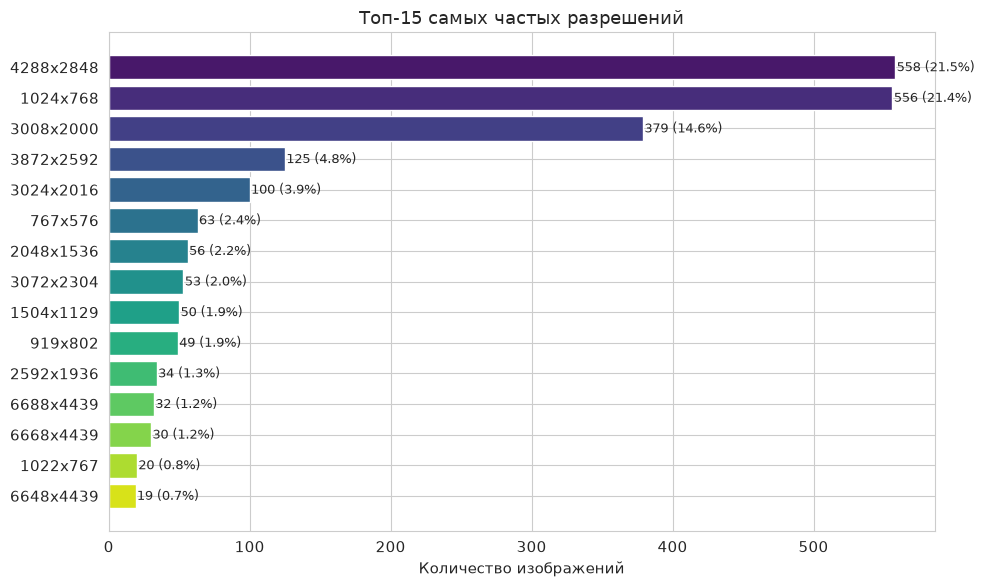

In [51]:
# 1.2 Мин / Макс разрешения
i_min, i_max = df_geom.area_mp.idxmin(), df_geom.area_mp.idxmax()

summary = pd.DataFrame({
    'min': [df_geom.width.min(), df_geom.height.min(), df_geom.area_mp.min(), df_geom.aspect_ratio.min()],
    'max': [df_geom.width.max(), df_geom.height.max(), df_geom.area_mp.max(), df_geom.aspect_ratio.max()],
    'mean': [df_geom.width.mean(), df_geom.height.mean(), df_geom.area_mp.mean(), df_geom.aspect_ratio.mean()],
    'median': [df_geom.width.median(), df_geom.height.median(), df_geom.area_mp.median(), df_geom.aspect_ratio.median()],
}, index=['width, px', 'height, px', 'area, MP', 'aspect ratio'])
display(summary.round(4))

print(f"Минимальное разрешение (по площади): {df_geom.width[i_min]}x{df_geom.height[i_min]}  ({df_geom.image_id[i_min]})")
print(f"Максимальное разрешение (по площади): {df_geom.width[i_max]}x{df_geom.height[i_max]}  ({df_geom.image_id[i_max]})")
print(f"Уникальных разрешений: {df_geom[['width', 'height']].drop_duplicates().shape[0]}")

top_res = (df_geom.groupby(['width', 'height']).size().sort_values(ascending=False)
           .head(15).reset_index(name='count'))
top_res['label'] = top_res.width.astype(str) + 'x' + top_res.height.astype(str)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(top_res.label, top_res['count'], color=sns.color_palette('viridis', len(top_res)))
ax.invert_yaxis()
for b, c in zip(bars, top_res['count']):
    ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, f'{c} ({100 * c / len(df_geom):.1f}%)', va='center', fontsize=9)
ax.set_xlabel('Количество изображений')
ax.set_title('Топ-15 самых частых разрешений')
plt.tight_layout()
fig.savefig(FIG_DIR / 'geometry_top_resolutions.png', dpi=150)
plt.show()

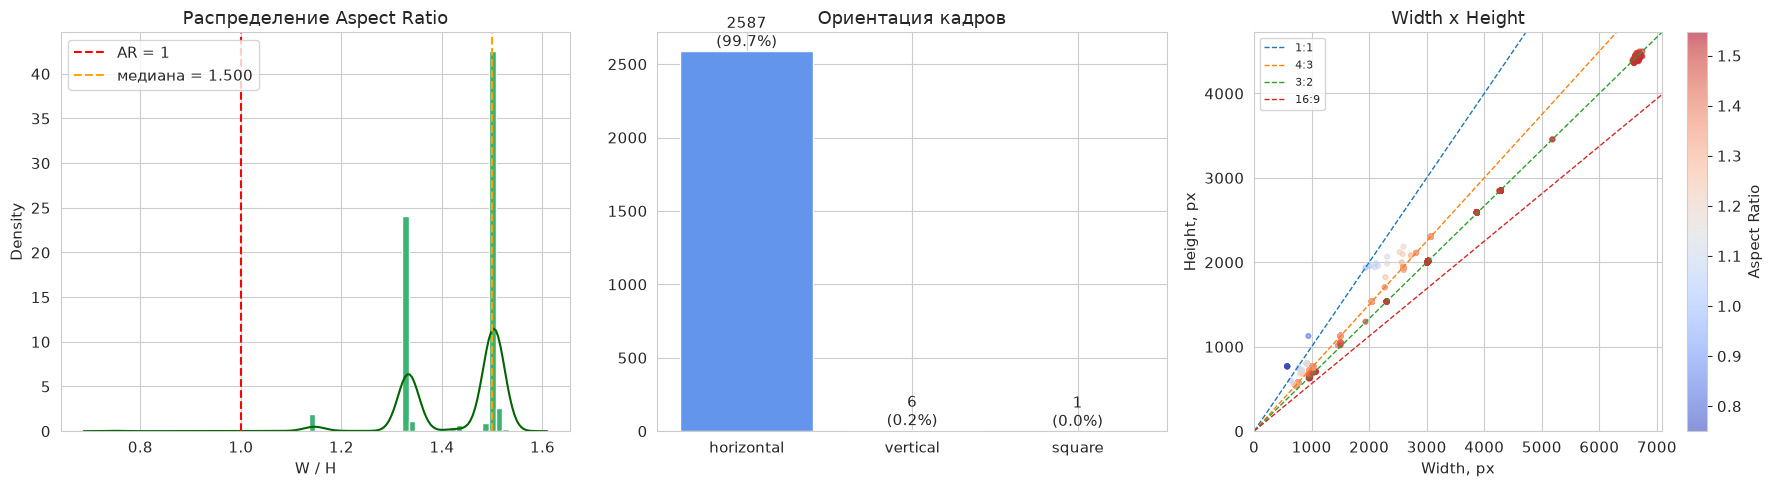

,count,mean,std,min,25%,50%,75%,max
aspect_ratio,2594.0,1.4319,0.1006,0.75,1.3333,1.5,1.5056,1.5465


In [52]:
# 1.3 Распределение Aspect Ratio
ar = df_geom.aspect_ratio

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(ar, bins=60, color='mediumseagreen', edgecolor='white', density=True)
sns.kdeplot(ar, ax=axes[0], color='darkgreen')
axes[0].axvline(1, color='red', ls='--', label='AR = 1')
axes[0].axvline(ar.median(), color='orange', ls='--', label=f'медиана = {ar.median():.3f}')
axes[0].set_title('Распределение Aspect Ratio')
axes[0].set_xlabel('W / H')
axes[0].legend()

orient_counts = df_geom.orientation.value_counts()
axes[1].bar(orient_counts.index, orient_counts.values, color=['cornflowerblue', 'salmon', 'gray'][:len(orient_counts)])
for i, v in enumerate(orient_counts.values):
    axes[1].text(i, v, f'{v}\n({100 * v / len(df_geom):.1f}%)', ha='center', va='bottom')
axes[1].set_title('Ориентация кадров')

sc = axes[2].scatter(df_geom.width, df_geom.height, c=ar, cmap='coolwarm', s=12, alpha=0.6)
plt.colorbar(sc, ax=axes[2], label='Aspect Ratio')
xs = np.linspace(0, df_geom.width.max() * 1.05, 100)
for lbl, r in [('1:1', 1), ('4:3', 4 / 3), ('3:2', 3 / 2), ('16:9', 16 / 9)]:
    axes[2].plot(xs, xs / r, '--', lw=1, label=lbl)
axes[2].set_xlim(0, df_geom.width.max() * 1.05)
axes[2].set_ylim(0, df_geom.height.max() * 1.05)
axes[2].set_xlabel('Width, px'); axes[2].set_ylabel('Height, px')
axes[2].set_title('Width x Height')
axes[2].legend(fontsize=8)

plt.tight_layout()
fig.savefig(FIG_DIR / 'geometry_aspect_ratio.png', dpi=150)
plt.show()
display(ar.describe().to_frame('aspect_ratio').T.round(4))

📄 Беру готовые данные из extreme_frames.csv (датасет не сканируем)


,type,image_id,width,height,aspect_ratio,area_mp
0,vertical,ISIC_0000243,576,768,0.7500,0.4424
1,vertical,ISIC_0000252,576,768,0.7500,0.4424
2,vertical,ISIC_0000253,576,768,0.7500,0.4424
3,vertical,ISIC_0000262,576,768,0.7500,0.4424
4,vertical,ISIC_0000269,576,768,0.7500,0.4424
5,horizontal,ISIC_0000167,965,624,1.5465,0.6022
6,horizontal,ISIC_0000157,963,629,1.5310,0.6057
7,horizontal,ISIC_0000183,1079,705,1.5305,0.7607
8,horizontal,ISIC_0014770,6682,4382,1.5249,29.2805
9,horizontal,ISIC_0000177,1069,703,1.5206,0.7515


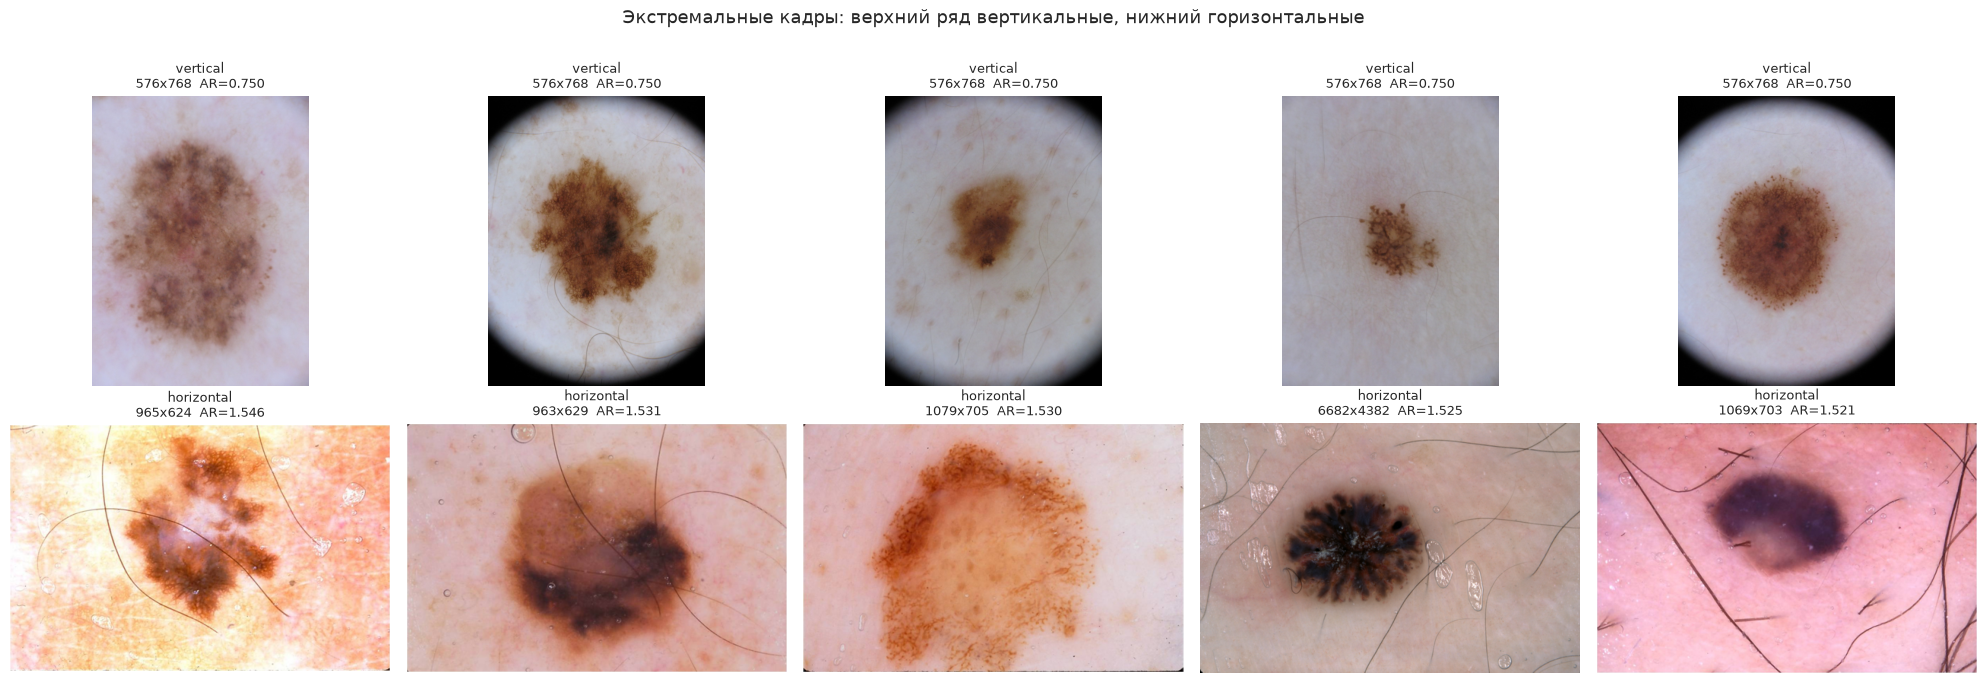

In [53]:
# 1.4 Экстремальные вертикальные / горизонтальные кадры (топ-5 каждого типа)
EXTREME_CSV = CSV_DIR / 'extreme_frames.csv'


def compute_extremes(top_n=5):
    v = df_geom.nsmallest(top_n, 'aspect_ratio').assign(type='vertical')
    h = df_geom.nlargest(top_n, 'aspect_ratio').assign(type='horizontal')
    out = pd.concat([v, h], ignore_index=True)
    return out.merge(df_index[['image_id', 'image_path']], on='image_id')


df_extreme = cached_csv(EXTREME_CSV, compute_extremes)
display(df_extreme[['type', 'image_id', 'width', 'height', 'aspect_ratio', 'area_mp']].round(4))

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, (_, r) in zip(axes.ravel(), df_extreme.iterrows()):
    with Image.open(r.image_path) as im:
        im = im.convert('RGB')
        im.thumbnail((500, 500))
        ax.imshow(im)
    ax.set_title(f'{r.type}\n{r.width}x{r.height}  AR={r.aspect_ratio:.3f}', fontsize=9)
    ax.axis('off')
plt.suptitle('Экстремальные кадры: верхний ряд вертикальные, нижний горизонтальные', y=1.0)
plt.tight_layout()
fig.savefig(FIG_DIR / 'geometry_extreme_frames.png', dpi=130)
plt.show()

---
## 2. Дисбаланс классов (пиксельный анализ)

Считает точный процент покрытия кадра опухолью, ищет пустые маски и маски-пустышки.
За один проход по маскам считаем сразу всё, что нужно для пунктов 2, 3 и 5 (площадь, центроид, bbox) и накапливаем сумму масок для тепловой карты.
Результаты: `csv_outputs/mask_stats.csv`, `csv_outputs/heatmap_sum.npy`, `csv_outputs/suspicious_masks.csv`.

In [54]:
# 2.1 Единый проход по маскам (выполняется только если нет mask_stats.csv и heatmap_sum.npy)
MASK_CSV = CSV_DIR / 'mask_stats.csv'
HEAT_NPY = CSV_DIR / 'heatmap_sum.npy'
HM_SIZE = 256            # размер тепловой карты (в нормированных координатах кадра)
TINY_PCT = 0.5           # маска < 0.5% кадра считается "пустышкой"
FULL_PCT = 95.0          # маска > 95% кадра подозрительна (почти весь кадр - опухоль)


def _mask_task(row):
    with Image.open(row.mask_path) as m:
        arr = np.asarray(m.convert('L'))
    h, w = arr.shape
    b = arr > 127
    lesion = int(b.sum())
    total = h * w
    rec = {
        'image_id': row.image_id, 'mask_width': w, 'mask_height': h,
        'total_pixels': total, 'lesion_pixels': lesion,
        'lesion_pct': 100.0 * lesion / total,
        'non_binary': bool(((arr != 0) & (arr != 255)).any()),
        'cx': np.nan, 'cy': np.nan, 'bbox_w_frac': np.nan, 'bbox_h_frac': np.nan, 'touches_border': False,
    }
    if lesion:
        col, rw = b.sum(axis=0), b.sum(axis=1)
        rec['cx'] = ((col * np.arange(w)).sum() / lesion + 0.5) / w     # центроид в долях кадра (0..1)
        rec['cy'] = ((rw * np.arange(h)).sum() / lesion + 0.5) / h
        xc, yc = np.flatnonzero(col), np.flatnonzero(rw)
        rec['bbox_w_frac'] = (xc[-1] - xc[0] + 1) / w
        rec['bbox_h_frac'] = (yc[-1] - yc[0] + 1) / h
        rec['touches_border'] = bool(xc[0] == 0 or yc[0] == 0 or xc[-1] == w - 1 or yc[-1] == h - 1)
    small = np.asarray(Image.fromarray((b * 255).astype(np.uint8)).resize((HM_SIZE, HM_SIZE), Image.BILINEAR),
                       dtype=np.float32) / 255.0
    return rec, small


if MASK_CSV.exists() and HEAT_NPY.exists() and not FORCE_RECOMPUTE:
    print('📄 Беру готовые mask_stats.csv и heatmap_sum.npy (маски не читаем)')
    df_mask = pd.read_csv(MASK_CSV)
    heat_sum = np.load(HEAT_NPY)
else:
    res = parallel_map(_mask_task, list(df_index.itertuples(index=False)), desc='Маски')
    df_mask = pd.DataFrame([r[0] for r in res])
    heat_sum = np.sum([r[1] for r in res], axis=0)
    df_mask['is_empty'] = df_mask.lesion_pixels == 0
    df_mask['is_tiny'] = (df_mask.lesion_pixels > 0) & (df_mask.lesion_pct < TINY_PCT)
    df_mask['is_full'] = df_mask.lesion_pct > FULL_PCT
    df_mask.to_csv(MASK_CSV, index=False)
    np.save(HEAT_NPY, heat_sum)
    print(f'💾 Сохранено: {MASK_CSV.name}, {HEAT_NPY.name}')

df_mask.head()

📄 Беру готовые mask_stats.csv и heatmap_sum.npy (маски не читаем)


,image_id,mask_width,mask_height,total_pixels,lesion_pixels,lesion_pct,non_binary,cx,cy,bbox_w_frac,bbox_h_frac,touches_border,is_empty,is_tiny,is_full
0,ISIC_0000000,1022,767,783874,368211,46.973238,False,0.488860,0.478974,0.833659,0.769231,False,False,False,False
1,ISIC_0000001,1022,767,783874,55266,7.050368,False,0.490052,0.466845,0.292564,0.331160,False,False,False,False
2,ISIC_0000003,1022,767,783874,263828,33.656940,False,0.526665,0.466264,0.586106,0.850065,False,False,False,False
3,ISIC_0000004,1022,767,783874,270416,34.497381,False,0.443375,0.485100,0.527397,0.863103,False,False,False,False
4,ISIC_0000006,1022,767,783874,71899,9.172265,False,0.468221,0.471431,0.286693,0.456323,False,False,False,False


ДИСБАЛАНС КЛАССОВ (пиксельный)
Всего пикселей             : 24,102,335,090
Пикселей опухоли (класс 1) : 5,452,345,907  (22.622%)
Пикселей фона    (класс 0) : 18,649,989,183  (77.378%)
Соотношение фон : опухоль  = 3.42 : 1   (pos_weight для BCE ~ 3.42)
----------------------------------------------------------------
Покрытие кадра опухолью по изображениям, %:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
lesion_pct,2594.0,21.4021,20.8366,0.2977,0.7762,1.5467,5.1731,13.8084,31.8733,65.1781,88.1741,98.665


Не бинарные маски (значения не 0/255): 0


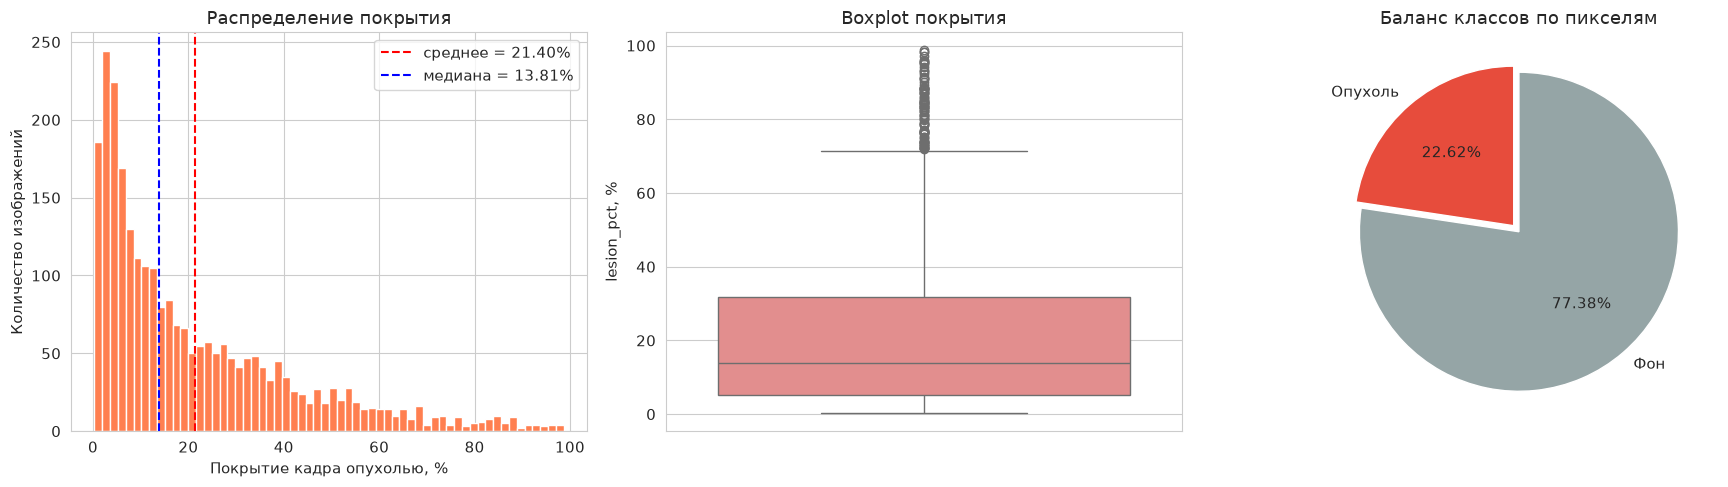

In [55]:
# 2.2 Точный процент покрытия и дисбаланс классов
tot_px = df_mask.total_pixels.sum()
les_px = df_mask.lesion_pixels.sum()
bg_px = tot_px - les_px

print('=' * 64)
print('ДИСБАЛАНС КЛАССОВ (пиксельный)')
print('=' * 64)
print(f'Всего пикселей             : {tot_px:,}')
print(f'Пикселей опухоли (класс 1) : {les_px:,}  ({100 * les_px / tot_px:.3f}%)')
print(f'Пикселей фона    (класс 0) : {bg_px:,}  ({100 * bg_px / tot_px:.3f}%)')
print(f'Соотношение фон : опухоль  = {bg_px / les_px:.2f} : 1   (pos_weight для BCE ~ {bg_px / les_px:.2f})')
print('-' * 64)
print('Покрытие кадра опухолью по изображениям, %:')
display(df_mask.lesion_pct.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame('lesion_pct').T.round(4))
print(f'Не бинарные маски (значения не 0/255): {int(df_mask.non_binary.sum())}')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(df_mask.lesion_pct, bins=60, color='coral', edgecolor='white')
axes[0].axvline(df_mask.lesion_pct.mean(), color='red', ls='--', label=f'среднее = {df_mask.lesion_pct.mean():.2f}%')
axes[0].axvline(df_mask.lesion_pct.median(), color='blue', ls='--', label=f'медиана = {df_mask.lesion_pct.median():.2f}%')
axes[0].set_xlabel('Покрытие кадра опухолью, %'); axes[0].set_ylabel('Количество изображений')
axes[0].set_title('Распределение покрытия'); axes[0].legend()

sns.boxplot(y=df_mask.lesion_pct, ax=axes[1], color='lightcoral')
axes[1].set_title('Boxplot покрытия'); axes[1].set_ylabel('lesion_pct, %')

axes[2].pie([les_px, bg_px], labels=['Опухоль', 'Фон'], autopct='%1.2f%%',
            colors=['#e74c3c', '#95a5a6'], startangle=90, explode=(0.05, 0))
axes[2].set_title('Баланс классов по пикселям')
plt.tight_layout()
fig.savefig(FIG_DIR / 'class_balance.png', dpi=150)
plt.show()

In [56]:
# 2.3 Пустые маски и маски-пустышки
SUSP_CSV = CSV_DIR / 'suspicious_masks.csv'

print(f'Пустые маски (0 пикселей опухоли)           : {int(df_mask.is_empty.sum())}')
print(f'Маски-пустышки (< {TINY_PCT}% кадра)               : {int(df_mask.is_tiny.sum())}')
print(f'Маски на весь кадр (> {FULL_PCT}% кадра)            : {int(df_mask.is_full.sum())}')

df_susp = df_mask[df_mask.is_empty | df_mask.is_tiny | df_mask.is_full].copy()
df_susp['reason'] = np.select([df_susp.is_empty, df_susp.is_tiny, df_susp.is_full], ['empty', 'tiny', 'full'], default='ok').astype(str)
df_susp = df_susp.sort_values('lesion_pct')
df_susp[['image_id', 'mask_width', 'mask_height', 'lesion_pixels', 'lesion_pct', 'reason']].to_csv(SUSP_CSV, index=False)
print(f'💾 {SUSP_CSV}')
display(df_susp[['image_id', 'lesion_pixels', 'lesion_pct', 'reason']].head(20))

# Совпадают ли размеры масок и изображений
chk = df_mask.merge(df_geom[['image_id', 'width', 'height']], on='image_id')
mism = chk[(chk.mask_width != chk.width) | (chk.mask_height != chk.height)]
print(f'\nМаски с размером, не совпадающим с изображением: {len(mism)}')

Пустые маски (0 пикселей опухоли)           : 0
Маски-пустышки (< 0.5% кадра)               : 8
Маски на весь кадр (> 95.0% кадра)            : 9
💾 /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/csv_outputs/suspicious_masks.csv


,image_id,lesion_pixels,lesion_pct,reason
1561,ISIC_0013196,17908,0.297673,tiny
2491,ISIC_0015951,19261,0.320163,tiny
1538,ISIC_0013155,25323,0.420928,tiny
1624,ISIC_0013355,52181,0.427285,tiny
1799,ISIC_0013798,43444,0.432872,tiny
1665,ISIC_0013456,54864,0.449255,tiny
1562,ISIC_0013197,27887,0.463547,tiny
1487,ISIC_0013027,48124,0.479503,tiny
2388,ISIC_0015229,28033536,95.217369,full
734,ISIC_0009988,750372,95.414734,full



Маски с размером, не совпадающим с изображением: 0


---
## 3. Пространственное смещение (Center Bias)

Тепловая карта локализации родинок: для каждого пикселя нормированного кадра (256x256) считается доля масок, где он принадлежит опухоли.
Результаты: `figures/lesion_heatmap.png`, `figures/center_bias.png`, `csv_outputs/center_bias_summary.csv`.

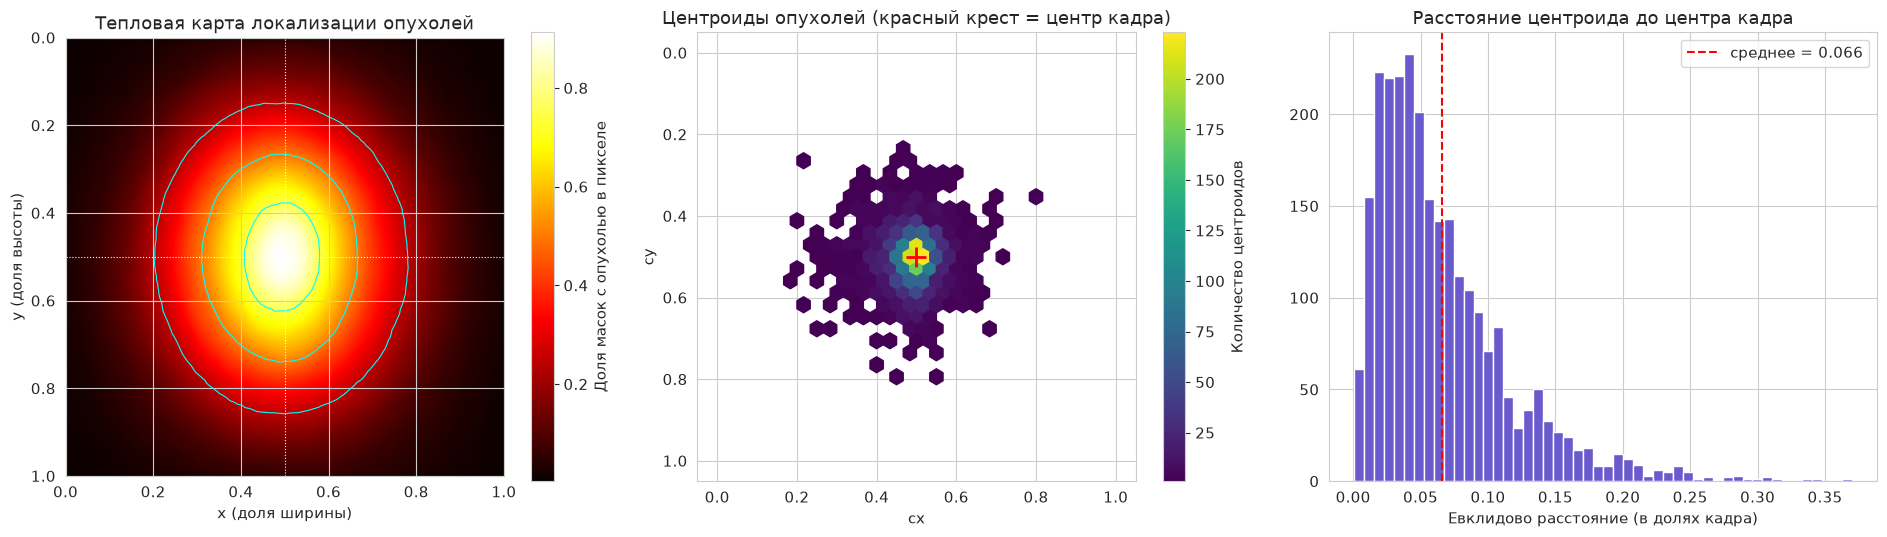

💾 figures/lesion_heatmap.png, figures/center_bias.png


In [57]:
# 3.1 Тепловая карта (берётся из heatmap_sum.npy, маски заново не читаем)
n_masks = len(df_mask)
heatmap = heat_sum / n_masks            # доля масок, где пиксель = опухоль (0..1)

# чистая картинка тепловой карты
plt.imsave(FIG_DIR / 'lesion_heatmap.png', heatmap, cmap='hot')

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

im = axes[0].imshow(heatmap, cmap='hot', extent=[0, 1, 1, 0])
axes[0].contour(np.linspace(0, 1, HM_SIZE), np.linspace(0, 1, HM_SIZE), heatmap,
                levels=[0.25, 0.5, 0.75], colors='cyan', linewidths=0.8)
axes[0].axvline(0.5, color='white', ls=':', lw=0.8); axes[0].axhline(0.5, color='white', ls=':', lw=0.8)
plt.colorbar(im, ax=axes[0], label='Доля масок с опухолью в пикселе')
axes[0].set_title('Тепловая карта локализации опухолей')
axes[0].set_xlabel('x (доля ширины)'); axes[0].set_ylabel('y (доля высоты)')

valid = df_mask.dropna(subset=['cx', 'cy'])
hb = axes[1].hexbin(valid.cx, valid.cy, gridsize=30, extent=(0, 1, 0, 1), cmap='viridis', mincnt=1)
plt.colorbar(hb, ax=axes[1], label='Количество центроидов')
axes[1].plot(0.5, 0.5, 'r+', ms=15, mew=2)
axes[1].invert_yaxis()  # y=0 сверху, как в координатах изображения
axes[1].set_title('Центроиды опухолей (красный крест = центр кадра)')
axes[1].set_xlabel('cx'); axes[1].set_ylabel('cy')

dist = np.sqrt((valid.cx - 0.5) ** 2 + (valid.cy - 0.5) ** 2)
axes[2].hist(dist, bins=50, color='slateblue', edgecolor='white')
axes[2].axvline(dist.mean(), color='red', ls='--', label=f'среднее = {dist.mean():.3f}')
axes[2].set_title('Расстояние центроида до центра кадра')
axes[2].set_xlabel('Евклидово расстояние (в долях кадра)'); axes[2].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / 'center_bias.png', dpi=150)
plt.show()
print('💾 figures/lesion_heatmap.png, figures/center_bias.png')

In [58]:
# 3.2 Количественная оценка центрированности
c0, c1 = int(HM_SIZE * 0.25), int(HM_SIZE * 0.75)
centre_mask = np.zeros_like(heatmap, dtype=bool)
centre_mask[c0:c1, c0:c1] = True        # центральная область = 25% площади кадра

dist = np.sqrt((valid.cx - 0.5) ** 2 + (valid.cy - 0.5) ** 2)
central_share = ((valid.cx - 0.5).abs() < 0.25) & ((valid.cy - 0.5).abs() < 0.25)

cb = {
    'n_masks_total': n_masks,
    'n_masks_with_lesion': len(valid),
    'mean_cx': valid.cx.mean(), 'mean_cy': valid.cy.mean(),
    'std_cx': valid.cx.std(), 'std_cy': valid.cy.std(),
    'mean_dist_to_center': dist.mean(),
    'median_dist_to_center': dist.median(),
    'pct_centroid_in_central_50x50': 100 * central_share.mean(),
    'heatmap_mean_center_region': heatmap[centre_mask].mean(),
    'heatmap_mean_outside_center': heatmap[~centre_mask].mean(),
    'center_to_border_ratio': heatmap[centre_mask].mean() / max(heatmap[~centre_mask].mean(), 1e-9),
    'heatmap_peak': heatmap.max(),
    'pct_touching_border': 100 * df_mask.touches_border.mean(),
}
df_cb = pd.DataFrame({'metric': list(cb.keys()), 'value': list(cb.values())})
df_cb.to_csv(CSV_DIR / 'center_bias_summary.csv', index=False)
display(df_cb.round(4))

print(f"\nЦентроид в центральной области (50% x 50% кадра): {cb['pct_centroid_in_central_50x50']:.1f}% масок")
print(f"Плотность опухолей в центре vs по краям: в {cb['center_to_border_ratio']:.2f} раза выше")
print(f"Опухоль касается края кадра в {cb['pct_touching_border']:.1f}% случаев")

,metric,value
0,n_masks_total,2594.0000
1,n_masks_with_lesion,2594.0000
2,mean_cx,0.4912
3,mean_cy,0.5027
4,std_cx,0.0544
5,std_cy,0.0613
6,mean_dist_to_center,0.0655
7,median_dist_to_center,0.0518
8,pct_centroid_in_central_50x50,99.4988
9,heatmap_mean_center_region,0.5287



Центроид в центральной области (50% x 50% кадра): 99.5% масок
Плотность опухолей в центре vs по краям: в 4.84 раза выше
Опухоль касается края кадра в 7.9% случаев


---
## 4. Кастомный цветовой профиль

Точные Mean и Std по каналам R, G, B для этого датасета. Считаем по **всем пикселям всех изображений** через точные суммы и суммы квадратов (по гистограмме каждого канала). Это не приближение через средние по картинкам.
Результаты: `csv_outputs/color_per_image.csv`, `csv_outputs/color_profile.csv`.

In [59]:
# 4.1 Суммы по каналам для каждого изображения (пропускается, если есть color_per_image.csv)
COLOR_CSV = CSV_DIR / 'color_per_image.csv'
CH = ['r', 'g', 'b']
VALS = np.arange(256, dtype=np.float64)


def _color_task(row):
    with Image.open(row.image_path) as im:
        arr = np.asarray(im.convert('RGB'))
    n = arr.shape[0] * arr.shape[1]
    rec = {'image_id': row.image_id, 'n_pixels': n}
    for i, c in enumerate(CH):
        hist = np.bincount(arr[:, :, i].ravel(), minlength=256).astype(np.float64)
        s, sq = (hist * VALS).sum(), (hist * VALS ** 2).sum()
        rec[f'sum_{c}'], rec[f'sumsq_{c}'] = s, sq
        rec[f'mean_{c}'] = s / n
        rec[f'std_{c}'] = float(np.sqrt(max(sq / n - (s / n) ** 2, 0.0)))
    return rec


def compute_color():
    rows = parallel_map(_color_task, list(df_index.itertuples(index=False)), workers=min(4, N_WORKERS), desc='Цвет')
    return pd.DataFrame(rows)


df_color = cached_csv(COLOR_CSV, compute_color)
df_color.head()

📄 Беру готовые данные из color_per_image.csv (датасет не сканируем)


,image_id,n_pixels,sum_r,sumsq_r,mean_r,std_r,sum_g,sumsq_g,mean_g,std_g,sum_b,sumsq_b,mean_b,std_b
0,ISIC_0000000,783874,103384140.0,1.554241e+10,131.888722,49.326056,116314553.0,2.120419e+10,148.384247,70.940987,133806845.0,2.870319e+10,170.699430,86.480040
1,ISIC_0000001,783874,130368446.0,2.223949e+10,166.313012,26.668975,127073322.0,2.140827e+10,162.109372,32.115486,129863454.0,2.255028e+10,165.668786,36.353720
2,ISIC_0000003,783874,149383773.0,3.003562e+10,190.571154,44.716112,138373900.0,2.736311e+10,176.525692,61.206339,131980516.0,2.635659e+10,168.369554,72.630547
3,ISIC_0000004,783874,70901922.0,1.380270e+10,90.450662,97.092710,53586072.0,8.379731e+09,68.360568,77.569218,62700283.0,1.118370e+10,79.987706,88.708418
4,ISIC_0000006,783874,105125960.0,1.477113e+10,134.110788,29.292492,115569094.0,1.798866e+10,147.433253,34.811537,131532434.0,2.351387e+10,167.797929,42.905212


,channel,mean_0_255,std_0_255,mean_0_1,std_0_1,imagenet_mean,imagenet_std,delta_mean,delta_std
0,R,181.17516,43.55493,0.71049,0.17080,0.485,0.229,0.22549,-0.05820
1,G,139.51466,43.65143,0.54712,0.17118,0.456,0.224,0.09112,-0.05282
2,B,128.25838,47.56641,0.50297,0.18653,0.406,0.225,0.09697,-0.03847


Пикселей учтено: 24,102,335,090

Для torchvision / albumentations:
  mean = [0.71049, 0.54712, 0.50297]
  std  = [0.1708, 0.17118, 0.18653]
  transforms.Normalize(mean=[0.71049, 0.54712, 0.50297], std=[0.1708, 0.17118, 0.18653])


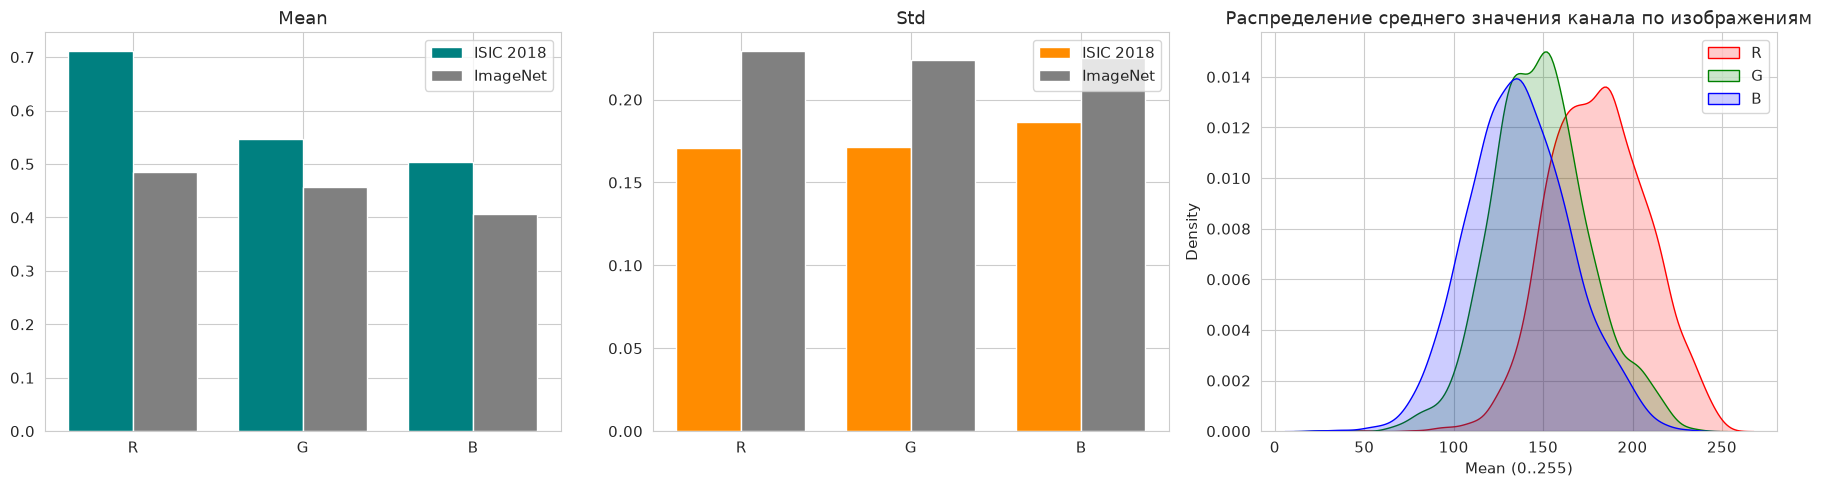

In [60]:
# 4.2 Итоговый Mean/Std датасета vs ImageNet
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD = np.array([0.229, 0.224, 0.225])

N = df_color.n_pixels.sum()
rows = []
for i, c in enumerate(CH):
    mean = df_color[f'sum_{c}'].sum() / N
    var = df_color[f'sumsq_{c}'].sum() / N - mean ** 2
    rows.append({
        'channel': c.upper(),
        'mean_0_255': mean, 'std_0_255': np.sqrt(var),
        'mean_0_1': mean / 255, 'std_0_1': np.sqrt(var) / 255,
        'imagenet_mean': IMAGENET_MEAN[i], 'imagenet_std': IMAGENET_STD[i],
    })
df_profile = pd.DataFrame(rows)
df_profile['delta_mean'] = df_profile.mean_0_1 - df_profile.imagenet_mean
df_profile['delta_std'] = df_profile.std_0_1 - df_profile.imagenet_std
df_profile.to_csv(CSV_DIR / 'color_profile.csv', index=False)
display(df_profile.round(5))

m = df_profile.mean_0_1.round(5).tolist()
s = df_profile.std_0_1.round(5).tolist()
print(f'Пикселей учтено: {N:,}')
print('\nДля torchvision / albumentations:')
print(f'  mean = {m}')
print(f'  std  = {s}')
print(f'  transforms.Normalize(mean={m}, std={s})')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
x = np.arange(3); wd = 0.38
axes[0].bar(x - wd / 2, df_profile.mean_0_1, wd, label='ISIC 2018', color='teal')
axes[0].bar(x + wd / 2, df_profile.imagenet_mean, wd, label='ImageNet', color='gray')
axes[0].set_xticks(x); axes[0].set_xticklabels(['R', 'G', 'B']); axes[0].set_title('Mean'); axes[0].legend()
axes[1].bar(x - wd / 2, df_profile.std_0_1, wd, label='ISIC 2018', color='darkorange')
axes[1].bar(x + wd / 2, df_profile.imagenet_std, wd, label='ImageNet', color='gray')
axes[1].set_xticks(x); axes[1].set_xticklabels(['R', 'G', 'B']); axes[1].set_title('Std'); axes[1].legend()
for c, col in zip(CH, ['red', 'green', 'blue']):
    sns.kdeplot(df_color[f'mean_{c}'], ax=axes[2], color=col, label=c.upper(), fill=True, alpha=0.2)
axes[2].set_title('Распределение среднего значения канала по изображениям')
axes[2].set_xlabel('Mean (0..255)'); axes[2].legend()
plt.tight_layout()
fig.savefig(FIG_DIR / 'color_profile.png', dpi=150)
plt.show()

---
## 5. Поиск выбросов и аномалий

Топ-5 самых маленьких и топ-5 самых больших опухолей (по доле пикселей кадра; пустые маски исключены, они разобраны в пункте 2).
Данные берутся из `mask_stats.csv`. Картинки читаются только для 10 найденных кадров.
Результаты: `csv_outputs/outliers_top5.csv`, `figures/outliers.png`.

💾 /home/dzmitry_tsetsiaruk/hse/med-image-analysis/EDA/csv_outputs/outliers_top5.csv


,type,rank,image_id,lesion_pixels,lesion_pct,cx,cy,touches_border
0,smallest,1,ISIC_0013196,17908,0.2977,0.4980,0.4828,False
1,smallest,2,ISIC_0015951,19261,0.3202,0.5118,0.4960,False
2,smallest,3,ISIC_0013155,25323,0.4209,0.5093,0.4829,False
3,smallest,4,ISIC_0013355,52181,0.4273,0.4437,0.5649,False
4,smallest,5,ISIC_0013798,43444,0.4329,0.5153,0.5147,False
5,largest,1,ISIC_0011356,775933,98.6650,0.4938,0.4942,True
6,largest,2,ISIC_0010189,772212,98.1918,0.4992,0.5002,True
7,largest,3,ISIC_0010204,771685,98.1248,0.5079,0.5079,True
8,largest,4,ISIC_0009990,764453,97.2052,0.4915,0.5037,True
9,largest,5,ISIC_0010056,755622,96.0823,0.5137,0.4878,True


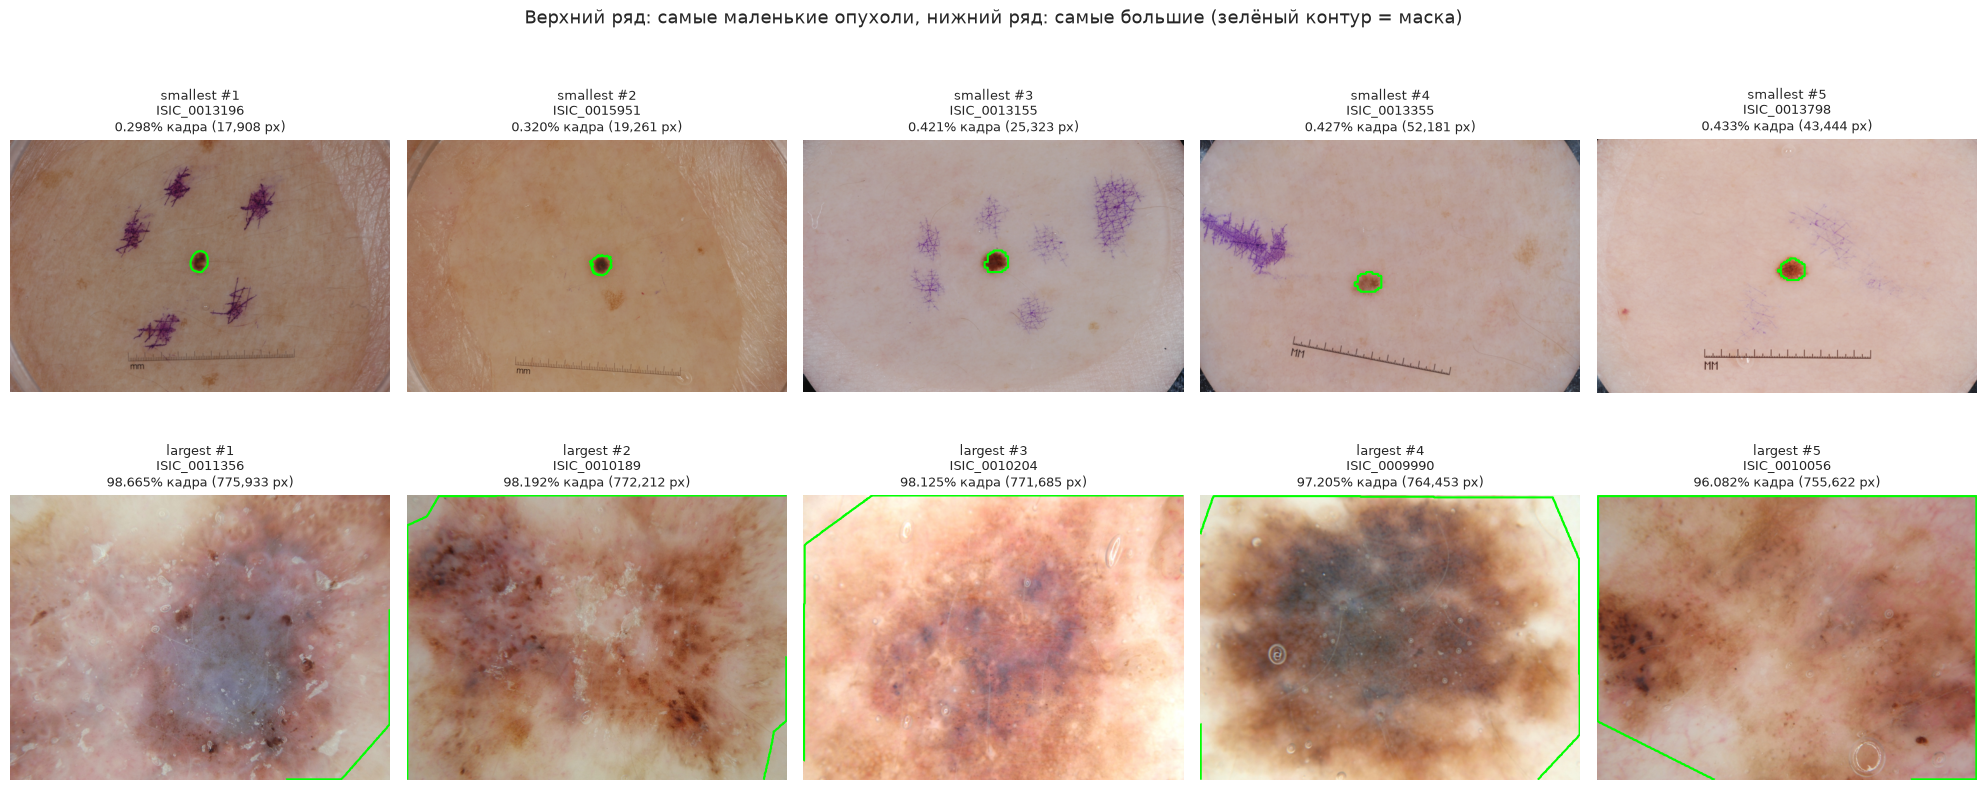

In [61]:
# 5.1 Топ-5 самых маленьких и самых больших опухолей
OUT_CSV = CSV_DIR / 'outliers_top5.csv'
TOP_N = 5

nonempty = df_mask[df_mask.lesion_pixels > 0]
small = nonempty.nsmallest(TOP_N, 'lesion_pct').assign(type='smallest')
large = nonempty.nlargest(TOP_N, 'lesion_pct').assign(type='largest')
df_out = pd.concat([small, large], ignore_index=True)
df_out['rank'] = list(range(1, TOP_N + 1)) * 2
df_out = df_out.merge(df_index[['image_id', 'image_path', 'mask_path']], on='image_id')
df_out[['type', 'rank', 'image_id', 'lesion_pixels', 'lesion_pct', 'mask_width', 'mask_height',
        'cx', 'cy', 'touches_border', 'image_path', 'mask_path']].to_csv(OUT_CSV, index=False)
print(f'💾 {OUT_CSV}')
display(df_out[['type', 'rank', 'image_id', 'lesion_pixels', 'lesion_pct', 'cx', 'cy', 'touches_border']].round(4))


def load_overlay(row, maxside=600):
    with Image.open(row.image_path) as im:
        im = im.convert('RGB')
        im.thumbnail((maxside, maxside))
    with Image.open(row.mask_path) as m:
        m = m.convert('L').resize(im.size, Image.NEAREST)
    return np.asarray(im), np.asarray(m) > 127


fig, axes = plt.subplots(2, TOP_N, figsize=(4 * TOP_N, 8.5))
for ax, (_, r) in zip(axes.ravel(), df_out.iterrows()):
    img, msk = load_overlay(r)
    ax.imshow(img)
    ax.contour(msk, levels=[0.5], colors='lime', linewidths=1.5)
    ax.set_title(f"{r.type} #{r['rank']}\n{r.image_id}\n{r.lesion_pct:.3f}% кадра ({r.lesion_pixels:,} px)", fontsize=9)
    ax.axis('off')
plt.suptitle('Верхний ряд: самые маленькие опухоли, нижний ряд: самые большие (зелёный контур = маска)', y=1.0)
plt.tight_layout()
fig.savefig(FIG_DIR / 'outliers.png', dpi=130)
plt.show()

In [62]:
# 5.2 Итог: все сохранённые файлы
print('CSV / NPY:')
for f in sorted(CSV_DIR.glob('*')):
    extra = ''
    if f.suffix == '.csv':
        extra = f'  строк: {sum(1 for _ in open(f, encoding="utf-8")) - 1}'
    print(f'  {f.name:<28} {f.stat().st_size / 1024:>8.1f} KB{extra}')
print('\nКартинки:')
for f in sorted(FIG_DIR.glob('*.png')):
    print(f'  {f.name:<32} {f.stat().st_size / 1024:>8.1f} KB')

CSV / NPY:
  center_bias_summary.csv           0.5 KB  строк: 14
  color_per_image.csv             541.4 KB  строк: 2594
  color_profile.csv                 0.5 KB  строк: 3
  dataset_index.csv               901.8 KB  строк: 2594
  extreme_frames.csv                2.3 KB  строк: 10
  heatmap_sum.npy                 256.1 KB
  image_geometry.csv              149.1 KB  строк: 2594
  mask_stats.csv                  398.1 KB  строк: 2594
  outliers_top5.csv                 4.5 KB  строк: 10
  suspicious_masks.csv              0.9 KB  строк: 17

Картинки:
  center_bias.png                     318.0 KB
  class_balance.png                   100.2 KB
  color_profile.png                   120.6 KB
  geometry_aspect_ratio.png           162.6 KB
  geometry_extreme_frames.png        1960.1 KB
  geometry_top_resolutions.png        107.3 KB
  lesion_heatmap.png                   24.5 KB
  outliers.png                       2438.0 KB
